In [4]:
"""
Fly a drone (quadrotor-shaped rigid body) from (0, 0, 1) to (3, 3, 3) in MuJoCo,
visualized with MuJoCo's built-in interactive 3D viewer.

Install requirements:
    pip install mujoco

Run:
    python mujoco_drone_flight.py

How it works
------------
- The drone is a single rigid body with a free joint (6 DOF: 3 translation + 3 rotation).
- Three "motor" actuators apply a world-frame force directly along the free joint's
  x/y/z translational DOFs (a simplified thrust model -- this skips individual rotor
  thrust mixing, which is unnecessary detail for a point-to-point flight demo).
- A minimum-jerk trajectory is generated from the start point to the goal point over
  a fixed duration, giving smooth position/velocity setpoints over time.
- A PD controller (with gravity feed-forward) tracks that trajectory by commanding
  the required world-frame force at every simulation step.
- After reaching the goal, the drone hovers in place.
"""

import time
import numpy as np
import mujoco
import mujoco.viewer

# ----------------------------------------------------------------------------
# 1. Build the drone model (MJCF)
# ----------------------------------------------------------------------------
# A central body + 4 arms + 4 rotor discs, purely for a quadrotor-like look.
# Physics is driven by 3 direct force actuators on the free joint (see below).

XML = """
<mujoco model="drone">
    <compiler angle="degree"/>
    <option timestep="0.002" gravity="0 0 -9.81"/>

    <visual>
        <headlight ambient="0.4 0.4 0.4" diffuse="0.6 0.6 0.6"/>
        <global offwidth="1280" offheight="720"/>
    </visual>

    <asset>
        <texture type="skybox" builtin="gradient" rgb1="0.65 0.8 0.95" rgb2="1 1 1" width="256" height="256"/>
        <texture name="grid" type="2d" builtin="checker" rgb1="0.75 0.8 0.75" rgb2="0.6 0.65 0.6" width="512" height="512"/>
        <material name="grid" texture="grid" texrepeat="8 8" reflectance="0.1"/>
    </asset>

    <worldbody>
        <light pos="0 0 6" dir="0 0 -1" diffuse="1 1 1" specular="0.2 0.2 0.2"/>
        <geom name="floor" type="plane" size="10 10 0.1" material="grid"/>

        <!-- markers for start and goal points -->
        <site name="start_marker" pos="0 0 1" size="0.06" rgba="0.1 0.8 0.1 0.6" type="sphere"/>
        <site name="goal_marker"  pos="3 3 3" size="0.06" rgba="0.9 0.1 0.1 0.6" type="sphere"/>

        <body name="drone" pos="0 0 1">
            <joint name="root" type="free"/>
            <inertial pos="0 0 0" mass="1.0" diaginertia="0.01 0.01 0.02"/>

            <!-- central hub -->
            <geom type="box" size="0.09 0.09 0.03" rgba="0.15 0.15 0.2 1" contype="0" conaffinity="0"/>

            <!-- 4 arms in an X configuration -->
            <geom type="capsule" fromto="0 0 0  0.22  0.22 0" size="0.012" rgba="0.2 0.2 0.25 1" contype="0" conaffinity="0"/>
            <geom type="capsule" fromto="0 0 0  0.22 -0.22 0" size="0.012" rgba="0.2 0.2 0.25 1" contype="0" conaffinity="0"/>
            <geom type="capsule" fromto="0 0 0 -0.22  0.22 0" size="0.012" rgba="0.2 0.2 0.25 1" contype="0" conaffinity="0"/>
            <geom type="capsule" fromto="0 0 0 -0.22 -0.22 0" size="0.012" rgba="0.2 0.2 0.25 1" contype="0" conaffinity="0"/>

            <!-- 4 rotor discs -->
            <geom type="cylinder" pos="0.22  0.22 0.01" size="0.09 0.005" rgba="0.1 0.5 0.9 0.5" contype="0" conaffinity="0"/>
            <geom type="cylinder" pos="0.22 -0.22 0.01" size="0.09 0.005" rgba="0.1 0.5 0.9 0.5" contype="0" conaffinity="0"/>
            <geom type="cylinder" pos="-0.22  0.22 0.01" size="0.09 0.005" rgba="0.9 0.3 0.1 0.5" contype="0" conaffinity="0"/>
            <geom type="cylinder" pos="-0.22 -0.22 0.01" size="0.09 0.005" rgba="0.9 0.3 0.1 0.5" contype="0" conaffinity="0"/>
        </body>
    </worldbody>

    <actuator>
        <!-- Direct world-frame force actuators along the free joint's translational DOFs.
             This is a simplified "ideal thrust vector" model -- fine for point-to-point
             flight demos where individual rotor mixing/attitude control isn't the point. -->
        <motor name="fx" joint="root" gear="1 0 0 0 0 0" ctrlrange="-30 30"/>
        <motor name="fy" joint="root" gear="0 1 0 0 0 0" ctrlrange="-30 30"/>
        <motor name="fz" joint="root" gear="0 0 1 0 0 0" ctrlrange="-30 30"/>
    </actuator>
</mujoco>
"""

# ----------------------------------------------------------------------------
# 2. Minimum-jerk trajectory generator
# ----------------------------------------------------------------------------
def min_jerk(p0, p1, t, T):
    """Return (position, velocity) along a minimum-jerk trajectory at time t in [0, T]."""
    t = np.clip(t / T, 0.0, 1.0)
    s = 10 * t**3 - 15 * t**4 + 6 * t**5          # position blend factor, 0 -> 1
    ds = (30 * t**2 - 60 * t**3 + 30 * t**4) / T   # d(blend)/dt
    pos = p0 + (p1 - p0) * s
    vel = (p1 - p0) * ds
    return pos, vel


# ----------------------------------------------------------------------------
# 3. Set up simulation
# ----------------------------------------------------------------------------
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)

start = np.array([0.0, 0.0, 1.0])
goal = np.array([3.0, 3.0, 3.0])
FLIGHT_TIME = 6.0   # seconds to travel from start to goal
HOVER_TIME = 3.0    # seconds to hover at the goal before the script exits

# Initial pose: start position, identity orientation, zero velocity
data.qpos[0:3] = start
data.qpos[3:7] = [1, 0, 0, 0]
data.qvel[:] = 0

drone_body_id = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "drone")
mass = model.body_mass[drone_body_id]
g = -model.opt.gravity[2]

# PD gains (tuned for a light, damped drone)
Kp = np.array([6.0, 6.0, 10.0])
Kd = np.array([4.0, 4.0, 6.0])

# ----------------------------------------------------------------------------
# 4. Run with the interactive viewer
# ----------------------------------------------------------------------------
with mujoco.viewer.launch_passive(model, data) as viewer:
    # A nice initial camera angle looking at the flight path
    viewer.cam.lookat[:] = (start + goal) / 2
    viewer.cam.distance = 7
    viewer.cam.azimuth = 135
    viewer.cam.elevation = -20

    total_time = FLIGHT_TIME + HOVER_TIME
    print(f"Flying drone from {start} to {goal} over {FLIGHT_TIME:.1f}s, "
          f"then hovering for {HOVER_TIME:.1f}s...")

    last_print = -1.0
    while viewer.is_running() and data.time < total_time:
        step_start = time.time()

        # Desired position/velocity from the trajectory (clamped to goal after FLIGHT_TIME)
        pos_des, vel_des = min_jerk(start, goal, data.time, FLIGHT_TIME)

        pos = data.qpos[0:3]
        vel = data.qvel[0:3]

        pos_err = pos_des - pos
        vel_err = vel_des - vel

        # Desired acceleration (PD) + gravity feed-forward
        accel_des = Kp * pos_err + Kd * vel_err + np.array([0, 0, g])
        force = mass * accel_des

        data.ctrl[0:3] = force

        mujoco.mj_step(model, data)
        viewer.sync()

        if data.time - last_print > 0.5:
            dist = np.linalg.norm(goal - pos)
            print(f"t={data.time:5.1f}s  pos=({pos[0]:5.2f}, {pos[1]:5.2f}, {pos[2]:5.2f})  "
                  f"dist_to_goal={dist:5.2f}")
            last_print = data.time

        # keep roughly real-time
        elapsed = time.time() - step_start
        if elapsed < model.opt.timestep:
            time.sleep(model.opt.timestep - elapsed)

    print("Done. Final position:", data.qpos[0:3])


Flying drone from [0. 0. 1.] to [3. 3. 3.] over 6.0s, then hovering for 3.0s...
t=  0.0s  pos=( 0.00,  0.00,  1.00)  dist_to_goal= 4.69
t=  0.5s  pos=( 0.01,  0.01,  1.01)  dist_to_goal= 4.68
t=  1.0s  pos=( 0.07,  0.07,  1.05)  dist_to_goal= 4.58
t=  1.5s  pos=( 0.25,  0.25,  1.18)  dist_to_goal= 4.30
t=  2.0s  pos=( 0.56,  0.56,  1.39)  dist_to_goal= 3.81
t=  2.5s  pos=( 0.98,  0.98,  1.67)  dist_to_goal= 3.15
t=  3.0s  pos=( 1.47,  1.47,  1.99)  dist_to_goal= 2.39
t=  3.5s  pos=( 1.96,  1.96,  2.31)  dist_to_goal= 1.63
t=  4.0s  pos=( 2.40,  2.40,  2.60)  dist_to_goal= 0.94
t=  4.5s  pos=( 2.75,  2.75,  2.82)  dist_to_goal= 0.40
t=  5.0s  pos=( 2.97,  2.97,  2.96)  dist_to_goal= 0.06
t=  5.5s  pos=( 3.06,  3.06,  3.02)  dist_to_goal= 0.09
t=  6.0s  pos=( 3.06,  3.06,  3.02)  dist_to_goal= 0.08
t=  6.5s  pos=( 3.02,  3.02,  3.01)  dist_to_goal= 0.03
t=  7.0s  pos=( 3.01,  3.01,  3.00)  dist_to_goal= 0.01
t=  7.5s  pos=( 3.00,  3.00,  3.00)  dist_to_goal= 0.00
t=  8.0s  pos=( 3.00,  3

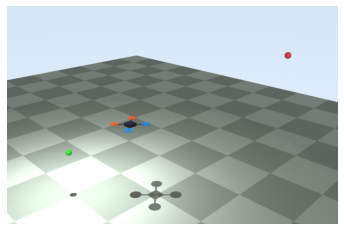

In [8]:
import cv2
import matplotlib.pyplot as plt
# Read the image
img = cv2.imread(r"D:\Semester 5 Projects\Drones\Drones_Translation.png")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 3. Display inline below the cell
plt.imshow(img_rgb)
plt.axis('off')  # Hides the grid axis lines
plt.show()


In [9]:
"""
Reproduction of:
M. Golestani, K. A. Alattas, S. Ud Din, S. Mobayen, A. K. Alanazi, A. Fekih,
"A Simple Structure Constrained Attitude Control for Rigid Bodies: A PD-Type
Control," IEEE Access, vol. 10, pp. 10202-10209, 2022.

This script implements exactly the model and controller in the paper. 
Rigid-body ATTITUDE dynamics in quaternions, 
a Finite-Time Prescribed Performance Function (FTPPF), 
and the constrained PD-type control law with an adaptive disturbance-bound estimator and actuator saturation. 
No physics engine is used -- like the paper, this is a direct numerical integration of the
closed-loop ODEs (via scipy), matching how the authors themselves would
have produced following Figures.

Notes on parameters NOT explicitly given a numeric value in the paper:
  - c (in s = omega + c*qv): the paper states c > 0 but never gives a
    number. We use c = 1.0; change C_GAIN below to explore sensitivity.
    
  - The FTPPF settling time Ts used for Part 2: the paper only varies Ts
    in Part 1 (15s, 10s). We use Ts = 10s for the Part 2 comparison.
    
  - sgn(s) in (13) is replaced by sat(s/zeta) (Remark 5 in the paper) with
    a small zeta, to avoid the chattering / stiffness of a true sign()
    function during numerical integration. Set USE_EXACT_SIGN = True to
    switch to the discontinuous version.
"""

import numpy as np
from scipy.integrate import solve_ivp
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ============================================================================
# 1. Physical model (Eq. 5 in the paper)
# ============================================================================
J = np.array([[20.0, 1.2, 0.9],
              [1.2, 17.0, 1.4],
              [0.9, 1.4, 15.0]])
J_inv = np.linalg.inv(J)

U_MAX = 2.5  # Nm, actuator saturation limit (same on all 3 axes)


def disturbance(t):
    """External disturbance d(t), as given in Section IV."""
    return np.array([0.05 * np.sin(t),
                      0.1 * np.sin(1.2 * t),
                      0.15 * np.sin(1.5 * t)])


def cross_matrix(z):
    """Skew-symmetric cross-product matrix z^x, Eq. (2)."""
    return np.array([[0, -z[2], z[1]],
                      [z[2], 0, -z[0]],
                      [-z[1], z[0], 0]])


def saturate(u, umax=U_MAX):
    """Actuator saturation, Eq. (3)-(4): equivalent to elementwise clipping."""
    return np.clip(u, -umax, umax)


# ============================================================================
# 2. Finite-Time Prescribed Performance Function, Eq. (8)
# ============================================================================
def ftppf(t, rho0, rhoT, kappa, Ts):
    """rho(t): scalar FTPPF value at time t (t may be a numpy array)."""
    t = np.atleast_1d(t).astype(float)
    out = np.empty_like(t)
    before = t < Ts
    # avoid divide-by-zero exactly at t == Ts
    tb = t[before]
    out[before] = (rho0 - rhoT * (1 + tb / Ts)) * np.exp(kappa * tb / (tb - Ts)) + rhoT
    out[~before] = rhoT
    return out if out.size > 1 else out[0]


# ============================================================================
# 3. Constrained PD-type controller, Eq. (11)-(14)
# ============================================================================
C_GAIN = 1.0            # c in s = omega + c*qv  (not numerically specified in paper)
USE_EXACT_SIGN = False   # False -> smoothed sgn via sat(s/zeta), per Remark 5
ZETA = 0.02


def smooth_sign(s, zeta=ZETA):
    return np.clip(s / zeta, -1.0, 1.0)


def constrained_controller(qv, omega, theta_hat, t, gains, ftppf_params):
    """Eq. (12)-(13): full constrained PD-type control law."""
    kp, kd, alpha, beta = gains["kp"], gains["kd"], gains["alpha"], gains["beta"]
    rho_q0, rho_qinf, kappa_q, Ts_q = ftppf_params["q"]
    rho_w0, rho_winf, kappa_w, Ts_w = ftppf_params["w"]

    rho_q = ftppf(t, rho_q0, rho_qinf, kappa_q, Ts_q)
    rho_w = ftppf(t, rho_w0, rho_winf, kappa_w, Ts_w)

    eps1 = qv / rho_q          # Eq. (11)
    eps2 = omega / rho_w

    s = omega + C_GAIN * qv

    sign_s = np.sign(s) if USE_EXACT_SIGN else smooth_sign(s)

    coeff = alpha * (1 - eps1) ** (-2) + beta * (1 - eps2) ** (-2)   # elementwise
    u_cons = coeff * s + theta_hat * sign_s

    u = -kp * qv - kd * omega - u_cons
    return u, s


def conventional_pd_controller(qv, omega, gains):
    """Plain PD control (Part 2 baseline): u = -kp*qv - kd*omega."""
    return -gains["kp"] * qv - gains["kd"] * omega


# ============================================================================
# 4. Closed-loop dynamics, Eq. (1)/(5) + adaptive law Eq. (14)
# ============================================================================
def rhs_constrained(t, x, gains, ftppf_params, eta1, eta2_func):
    qv, q4, omega, theta_hat = x[0:3], x[3], x[4:7], x[7]

    u, s = constrained_controller(qv, omega, theta_hat, t, gains, ftppf_params)
    u_applied = saturate(u)

    qv_dot = 0.5 * (q4 * np.eye(3) + cross_matrix(qv)) @ omega
    q4_dot = -0.5 * qv @ omega
    omega_dot = J_inv @ (-cross_matrix(omega) @ (J @ omega) + u_applied + disturbance(t))

    eta2 = eta2_func(t)
    theta_hat_dot = (np.linalg.norm(s) - eta2 * theta_hat) / eta1

    return np.concatenate([qv_dot, [q4_dot], omega_dot, [theta_hat_dot]])


def rhs_pd(t, x, gains):
    qv, q4, omega = x[0:3], x[3], x[4:7]

    u = conventional_pd_controller(qv, omega, gains)
    u_applied = saturate(u)

    qv_dot = 0.5 * (q4 * np.eye(3) + cross_matrix(qv)) @ omega
    q4_dot = -0.5 * qv @ omega
    omega_dot = J_inv @ (-cross_matrix(omega) @ (J @ omega) + u_applied + disturbance(t))

    return np.concatenate([qv_dot, [q4_dot], omega_dot])


def recover_control(t_arr, x_arr, gains, ftppf_params=None, mode="constrained"):
    """Recompute the (saturated) control torque history for plotting."""
    u_hist = np.zeros((3, len(t_arr)))
    for i, t in enumerate(t_arr):
        if mode == "constrained":
            qv, omega, theta_hat = x_arr[0:3, i], x_arr[4:7, i], x_arr[7, i]
            u, _ = constrained_controller(qv, omega, theta_hat, t, gains, ftppf_params)
        else:
            qv, omega = x_arr[0:3, i], x_arr[4:7, i]
            u = conventional_pd_controller(qv, omega, gains)
        u_hist[:, i] = saturate(u)
    return u_hist


# ============================================================================
# 5. Common controller / FTPPF parameters (Section IV of the paper)
# ============================================================================
GAINS = dict(kp=40.0, kd=20.0, alpha=1.5, beta=1.2)
ETA1 = 0.1
ETA2_FUNC = lambda t: 2 * np.exp(-0.5 * t)

RHO_Q0, RHO_QINF = 0.3, 0.008
RHO_W0, RHO_WINF = 0.4, 0.005
KAPPA = 2.5  # called sigma_q, sigma_w in the paper's parameter list

T_SPAN = (0.0, 20.0)
T_EVAL = np.linspace(*T_SPAN, 2000)


def make_ftppf_params(Ts):
    return {"q": (RHO_Q0, RHO_QINF, KAPPA, Ts),
            "w": (RHO_W0, RHO_WINF, KAPPA, Ts)}


def simulate_constrained(q0, w0, Ts):
    x0 = np.concatenate([q0[0:3], [q0[3]], w0, [0.0]])  # theta_hat(0) = 0
    ftppf_params = make_ftppf_params(Ts)
    sol = solve_ivp(rhs_constrained, T_SPAN, x0, t_eval=T_EVAL, method="RK45",
                     max_step=0.01, args=(GAINS, ftppf_params, ETA1, ETA2_FUNC))
    u_hist = recover_control(sol.t, sol.y, GAINS, ftppf_params, mode="constrained")
    return sol.t, sol.y, u_hist, ftppf_params


def simulate_pd(q0, w0):
    x0 = np.concatenate([q0[0:3], [q0[3]], w0])
    sol = solve_ivp(rhs_pd, T_SPAN, x0, t_eval=T_EVAL, method="RK45",
                     max_step=0.01, args=(GAINS,))
    u_hist = recover_control(sol.t, sol.y, GAINS, mode="pd")
    return sol.t, sol.y, u_hist


# ============================================================================
# 6. PART 1 -- effect of the FTPPF settling time Ts (Figs. 4-6)
# ============================================================================
q0_part1 = np.array([0.2, -0.15, -0.25, 0.9354])
w0_part1 = np.array([0.03, 0.02, -0.01])

results_part1 = {}
for Ts in (15.0, 10.0):
    t, x, u, ftppf_params = simulate_constrained(q0_part1, w0_part1, Ts)
    results_part1[Ts] = (t, x, u, ftppf_params)

# --- Fig. 4 equivalent: quaternion vector part vs its FTPPF envelope ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, Ts in zip(axes, (15.0, 10.0)):
    t, x, u, ftppf_params = results_part1[Ts]
    rho_q = ftppf(t, *ftppf_params["q"])
    ax.fill_between(t, -rho_q, rho_q, color="0.85", label=r"$\pm\rho_q(t)$")
    labels = [r"$q_1$", r"$q_2$", r"$q_3$", r"$q_4$"]
    for i in range(3):
        ax.plot(t, x[i], label=labels[i])
    ax.plot(t, x[3], label=labels[3])
    ax.set_title(f"$T_s$ = {Ts:g} s")
    ax.set_xlabel("Time (s)")
    ax.set_ylim(-1, 1)
axes[0].set_ylabel("Quaternion")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Part 1 - Quaternion trajectories vs FTPPF bound (paper Fig. 4)")
fig.tight_layout()
fig.savefig("D:/Semester 5 Projects/part1_quaternion.png", dpi=140)

# --- Fig. 5 equivalent: angular velocity vs FTPPF envelope ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, Ts in zip(axes, (15.0, 10.0)):
    t, x, u, ftppf_params = results_part1[Ts]
    rho_w = ftppf(t, *ftppf_params["w"])
    ax.fill_between(t, -rho_w, rho_w, color="0.85", label=r"$\pm\rho_\omega(t)$")
    for i, lab in enumerate([r"$\omega_1$", r"$\omega_2$", r"$\omega_3$"]):
        ax.plot(t, x[4 + i], label=lab)
    ax.set_title(f"$T_s$ = {Ts:g} s")
    ax.set_xlabel("Time (s)")
    ax.set_ylim(-0.4, 0.4)
axes[0].set_ylabel("Angular velocity (rad/s)")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Part 1 - Angular velocity trajectories vs FTPPF bound (paper Fig. 5)")
fig.tight_layout()
fig.savefig("D:/Semester 5 Projects/part1_omega.png", dpi=140)

# --- Fig. 6 equivalent: control torque ---
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, Ts in zip(axes, (15.0, 10.0)):
    t, x, u, ftppf_params = results_part1[Ts]
    for i, lab in enumerate([r"$\tau_1$", r"$\tau_2$", r"$\tau_3$"]):
        ax.plot(t, u[i], label=lab)
    ax.axhline(U_MAX, color="k", lw=0.8, ls="--")
    ax.axhline(-U_MAX, color="k", lw=0.8, ls="--")
    ax.set_title(f"$T_s$ = {Ts:g} s")
    ax.set_xlabel("Time (s)")
axes[0].set_ylabel("Control torque (Nm)")
axes[0].legend(loc="upper right", fontsize=8)
fig.suptitle("Part 1 - Control torque, saturated at \u00b12.5 Nm (paper Fig. 6)")
fig.tight_layout()
fig.savefig("D:/Semester 5 Projects/part1_torque.png", dpi=140)

# ============================================================================
# 7. PART 2 -- constrained PD-type control vs conventional PD (Figs. 7-9)
# ============================================================================
q0_part2 = np.array([0.3, -0.2, -0.3, 0.8832])
w0_part2 = np.array([-0.02, -0.02, 0.025])
TS_PART2 = 10.0  # not explicitly given in the paper's Part 2 text; see module docstring

t_c, x_c, u_c, ftppf_params2 = simulate_constrained(q0_part2, w0_part2, TS_PART2)
t_p, x_p, u_p = simulate_pd(q0_part2, w0_part2)

# --- Fig. 7 equivalent: quaternion, constrained vs conventional PD ---
fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)
rho_q2 = ftppf(t_c, *ftppf_params2["q"])
for i, ax in enumerate(axes):
    ax.fill_between(t_c, -rho_q2, rho_q2, color="0.85")
    ax.plot(t_c, x_c[i], label="Constrained PD-type")
    ax.plot(t_p, x_p[i], "--", label="Conventional PD")
    ax.set_ylabel(f"$q_{i+1}$")
    ax.set_ylim(-0.5, 0.5)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Part 2 - Quaternion: constrained vs conventional PD (paper Fig. 7)")
fig.tight_layout()
fig.savefig("D:/Semester 5 Projects/part2_quaternion.png", dpi=140)

# --- Fig. 8 equivalent: angular velocity, constrained vs conventional PD ---
fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)
rho_w2 = ftppf(t_c, *ftppf_params2["w"])
for i, ax in enumerate(axes):
    ax.fill_between(t_c, -rho_w2, rho_w2, color="0.85")
    ax.plot(t_c, x_c[4 + i], label="Constrained PD-type")
    ax.plot(t_p, x_p[4 + i], "--", label="Conventional PD")
    ax.set_ylabel(f"$\\omega_{i+1}$")
    ax.set_ylim(-0.5, 0.5)
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Part 2 - Angular velocity: constrained vs conventional PD (paper Fig. 8)")
fig.tight_layout()
fig.savefig("D:/Semester 5 Projects/part2_omega.png", dpi=140)

# --- Fig. 9 equivalent: control torque, constrained vs conventional PD ---
fig, axes = plt.subplots(3, 1, figsize=(6, 9), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(t_c, u_c[i], label="Constrained PD-type")
    ax.plot(t_p, u_p[i], "--", label="Conventional PD")
    ax.axhline(U_MAX, color="k", lw=0.8, ls=":")
    ax.axhline(-U_MAX, color="k", lw=0.8, ls=":")
    ax.set_ylabel(f"$u_{i+1}$ (Nm)")
axes[0].legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("Time (s)")
fig.suptitle("Part 2 - Control torque: constrained vs conventional PD (paper Fig. 9)")
fig.tight_layout()
fig.savefig("D:/Semester 5 Projects/part2_torque.png", dpi=140)

print("Done. Saved 6 PNGs to D:/Semester 5 Projects/")
print("Final ||qv|| (constrained, Part 2):", np.linalg.norm(x_c[0:3, -1]))
print("Final ||qv|| (conventional PD, Part 2):", np.linalg.norm(x_p[0:3, -1]))


KeyboardInterrupt: 

In [11]:
"""
3D viewer for the Golestani et al. (2022) attitude-control reproduction.

Same physics and same control laws as paper_attitude_control_sim.py, but
instead of matplotlib plots, this drives two real MuJoCo rigid bodies
("satellites") in the native 3D viewer:

    LEFT  body (blue accents)  -> the paper's constrained PD-type control (Eq. 12-13)
    RIGHT body (orange accents) -> conventional PD control (baseline, Part 2)

Both bodies share the paper's exact inertia matrix J, start from the same
initial attitude/angular velocity (Part 2's initial condition), and feel the
same external disturbance d(t). A thin gray "target" rod at each satellite
marks the goal pointing direction (world +x, i.e. the identity attitude);
the colored nose cone on each satellite is its body +x axis -- watch it
swing around and lock onto the gray rod.

Install:
    pip install mujoco

Run:
    python paper_attitude_control_viewer.py
"""

import time
import numpy as np
import mujoco
import mujoco.viewer

# ============================================================================
# 1. Paper's physical model (Eq. 1/5) -- identical to paper_attitude_control_sim.py
# ============================================================================
J = np.array([[20.0, 1.2, 0.9],
              [1.2, 17.0, 1.4],
              [0.9, 1.4, 15.0]])
U_MAX = 2.5  # Nm actuator saturation


def disturbance(t):
    return np.array([0.05 * np.sin(t),
                      0.1 * np.sin(1.2 * t),
                      0.15 * np.sin(1.5 * t)])


def saturate(u, umax=U_MAX):
    return np.clip(u, -umax, umax)


def ftppf(t, rho0, rhoT, kappa, Ts):
    if t < Ts:
        return (rho0 - rhoT * (1 + t / Ts)) * np.exp(kappa * t / (t - Ts)) + rhoT
    return rhoT


# ============================================================================
# 2. Constrained PD-type controller (Eq. 11-14) and conventional PD baseline
# ============================================================================
C_GAIN = 1.0     # s = omega + c*qv  (paper doesn't give a numeric value for c)
ZETA = 0.02      # smoothing width for sat(s/zeta) in place of sgn(s), Remark 5

GAINS = dict(kp=40.0, kd=20.0, alpha=1.5, beta=1.2)
ETA1 = 0.1
ETA2_FUNC = lambda t: 2 * np.exp(-0.5 * t)

RHO_Q0, RHO_QINF = 0.3, 0.008
RHO_W0, RHO_WINF = 0.4, 0.005
KAPPA = 2.5
TS = 10.0  # FTPPF settling time (not explicitly given for Part 2 in the paper)


def constrained_controller(qv, omega, theta_hat, t):
    rho_q = ftppf(t, RHO_Q0, RHO_QINF, KAPPA, TS)
    rho_w = ftppf(t, RHO_W0, RHO_WINF, KAPPA, TS)
    eps1 = qv / rho_q
    eps2 = omega / rho_w
    s = omega + C_GAIN * qv
    sign_s = np.clip(s / ZETA, -1.0, 1.0)
    coeff = GAINS["alpha"] * (1 - eps1) ** (-2) + GAINS["beta"] * (1 - eps2) ** (-2)
    u_cons = coeff * s + theta_hat * sign_s
    u = -GAINS["kp"] * qv - GAINS["kd"] * omega - u_cons
    return u, s


def conventional_pd_controller(qv, omega):
    return -GAINS["kp"] * qv - GAINS["kd"] * omega


# ============================================================================
# 3. Build the MJCF: two satellites with the paper's exact inertia tensor
# ============================================================================
# fullinertia order is Ixx Iyy Izz Ixy Ixz Iyz -> matches J above exactly.
FULLINERTIA = "20 17 15 1.2 0.9 1.4"

SAT_BODY_TEMPLATE = """
<body name="sat_{tag}" pos="{x} 0 1.5">
    <joint name="root_{tag}" type="free"/>
    <inertial pos="0 0 0" mass="6.0" fullinertia="{inertia}"/>

    <!-- central bus -->
    <geom type="box" size="0.18 0.18 0.18" rgba="{body_rgba}" contype="0" conaffinity="0"/>
    <!-- solar panels along body y -->
    <geom type="box" pos="0 0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 -0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <!-- nose cone marking the body +x axis -->
    <geom type="cylinder" fromto="0.18 0 0  0.45 0 0" size="0.05" rgba="{nose_rgba}" contype="0" conaffinity="0"/>
</body>
"""

XML = f"""
<mujoco model="attitude_paper_repro">
    <compiler angle="degree"/>
    <option timestep="0.002" gravity="0 0 0"/>

    <visual>
        <headlight ambient="0.4 0.4 0.4" diffuse="0.6 0.6 0.6"/>
    </visual>

    <asset>
        <texture type="skybox" builtin="gradient" rgb1="0.05 0.05 0.12" rgb2="0 0 0" width="256" height="256"/>
        <texture name="grid" type="2d" builtin="checker" rgb1="0.25 0.25 0.3" rgb2="0.18 0.18 0.22" width="512" height="512"/>
        <material name="grid" texture="grid" texrepeat="10 10" reflectance="0.05"/>
    </asset>

    <worldbody>
        <light pos="0 0 6" dir="0 0 -1" diffuse="1 1 1"/>
        <geom name="floor" type="plane" size="6 4 0.1" pos="0 0 0" material="grid"/>

        <!-- static "target" rods: world +x direction at each satellite's location,
             marking the goal attitude (identity quaternion) -->
        <geom type="cylinder" fromto="-1.5 0 1.5  -1.1 0 1.5" size="0.015" rgba="0.8 0.8 0.8 0.5" contype="0" conaffinity="0"/>
        <geom type="cylinder" fromto="1.5 0 1.5  1.9 0 1.5" size="0.015" rgba="0.8 0.8 0.8 0.5" contype="0" conaffinity="0"/>

        <!-- labels via small flags: blue = constrained, orange = conventional PD -->
        {SAT_BODY_TEMPLATE.format(tag="c", x=-1.5, inertia=FULLINERTIA,
                                   body_rgba="0.15 0.35 0.75 1", panel_rgba="0.1 0.5 0.9 0.6",
                                   nose_rgba="0.9 0.2 0.2 1")}
        {SAT_BODY_TEMPLATE.format(tag="pd", x=1.5, inertia=FULLINERTIA,
                                   body_rgba="0.8 0.45 0.1 1", panel_rgba="0.95 0.6 0.2 0.6",
                                   nose_rgba="0.9 0.2 0.2 1")}
    </worldbody>

    <actuator>
        <motor name="tx_c" joint="root_c" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_c" joint="root_c" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_c" joint="root_c" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
        <motor name="tx_pd" joint="root_pd" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_pd" joint="root_pd" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_pd" joint="root_pd" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
    </actuator>
</mujoco>
"""

# ============================================================================
# 4. Set up simulation
# ============================================================================
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)

jid_c = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_c")
jid_pd = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_pd")
qadr_c, dadr_c = model.jnt_qposadr[jid_c], model.jnt_dofadr[jid_c]
qadr_pd, dadr_pd = model.jnt_qposadr[jid_pd], model.jnt_dofadr[jid_pd]

# Paper's Part 2 initial condition: q(0) = [qv, q4], omega(0)
q0 = np.array([0.3, -0.2, -0.3, 0.8832])   # [q1, q2, q3, q4]  (q4 = scalar part)
w0 = np.array([-0.02, -0.02, 0.025])

for qadr, dadr in [(qadr_c, dadr_c), (qadr_pd, dadr_pd)]:
    # MuJoCo quaternion order is [w, x, y, z] (scalar-first);
    # the paper's is [q1, q2, q3, q4] with q4 as the scalar part -> reorder.
    data.qpos[qadr + 3: qadr + 7] = [q0[3], q0[0], q0[1], q0[2]]
    data.qvel[dadr + 3: dadr + 6] = w0

theta_hat_c = 0.0  # adaptive disturbance-bound estimate, Eq. (14), constrained sat only

T_END = 20.0

# ============================================================================
# 5. Run with the interactive viewer
# ============================================================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    viewer.cam.lookat[:] = [0, 0, 1.5]
    viewer.cam.distance = 6.5
    viewer.cam.azimuth = 100
    viewer.cam.elevation = -15

    print("LEFT (blue)  = paper's constrained PD-type control")
    print("RIGHT (orange) = conventional PD control")
    print("Watch the red nose cones swing onto the gray target rods.\n")

    last_print = -1.0
    while viewer.is_running() and data.time < T_END:
        step_start = time.time()
        t = data.time
        dt = model.opt.timestep

        # ---- constrained satellite ----
        quat_c = data.qpos[qadr_c + 3: qadr_c + 7]           # [w, x, y, z]
        qv_c, q4_c = quat_c[1:4], quat_c[0]
        omega_c = data.qvel[dadr_c + 3: dadr_c + 6]
        u_c, s_c = constrained_controller(qv_c, omega_c, theta_hat_c, t)
        data.ctrl[0:3] = saturate(u_c)
        eta2 = ETA2_FUNC(t)
        theta_hat_c += dt * (np.linalg.norm(s_c) - eta2 * theta_hat_c) / ETA1

        # ---- conventional-PD satellite ----
        quat_pd = data.qpos[qadr_pd + 3: qadr_pd + 7]
        qv_pd = quat_pd[1:4]
        omega_pd = data.qvel[dadr_pd + 3: dadr_pd + 6]
        u_pd = conventional_pd_controller(qv_pd, omega_pd)
        data.ctrl[3:6] = saturate(u_pd)

        # ---- shared external disturbance, applied as body-frame torque ----
        d = disturbance(t)
        data.qfrc_applied[dadr_c + 3: dadr_c + 6] = d
        data.qfrc_applied[dadr_pd + 3: dadr_pd + 6] = d

        mujoco.mj_step(model, data)
        viewer.sync()

        if t - last_print > 1.0:
            err_c = np.linalg.norm(qv_c)
            err_pd = np.linalg.norm(qv_pd)
            print(f"t={t:5.1f}s   |qv| constrained={err_c:6.4f}   |qv| conventional PD={err_pd:6.4f}")
            last_print = t

        elapsed = time.time() - step_start
        if elapsed < dt:
            time.sleep(dt - elapsed)

    print("\nDone.")

LEFT (blue)  = paper's constrained PD-type control
RIGHT (orange) = conventional PD control
Watch the red nose cones swing onto the gray target rods.

t=  0.0s   |qv| constrained=0.4690   |qv| conventional PD=0.4690


<ipython-input-11-1423d8cdb772>:78: RuntimeWarning: divide by zero encountered in power
  coeff = GAINS["alpha"] * (1 - eps1) ** (-2) + GAINS["beta"] * (1 - eps2) ** (-2)


t=  1.0s   |qv| constrained=0.4013   |qv| conventional PD=0.4013
t=  2.0s   |qv| constrained=0.2403   |qv| conventional PD=0.2140
t=  3.0s   |qv| constrained=0.1275   |qv| conventional PD=0.0309
t=  4.0s   |qv| constrained=0.0667   |qv| conventional PD=0.0479
t=  5.0s   |qv| constrained=0.0364   |qv| conventional PD=0.0404
t=  6.0s   |qv| constrained=0.0172   |qv| conventional PD=0.0158
t=  7.0s   |qv| constrained=0.0091   |qv| conventional PD=0.0028
t=  8.0s   |qv| constrained=0.0053   |qv| conventional PD=0.0067
t=  9.0s   |qv| constrained=0.0023   |qv| conventional PD=0.0055

Done.


The paper is solving an attitude (orientation) problem, not a navigation problem. 

The state being controlled is the quaternion q and angular velocity ω. There is no position variable p anywhere in their equations.

Physically, this models a spacecraft that's already where it needs to be (in orbit, in formation, etc.) but is pointing the wrong way, maybe its antenna, camera, or solar panels aren't aimed correctly and needs to reorient itself without necessarily going anywhere.


In [5]:
"""
Turn a rigid body to ANY user-requested orientation, using both controllers
from Golestani et al. (2022): 
the constrained PD-type control and a conventional PD baseline. 

Asks for a target orientation on start-up, 
then opens a MuJoCo 3D viewer showing both controllers chasing that target
side by side.

--------------------------------------------------------------------------
How the generalization works
--------------------------------------------------------------------------
The paper's controller only ever regulates the quaternion to the identity
attitude q_d = [0,0,0,1] (qv -> 0). To reach an ARBITRARY target attitude
q_d, we use the standard attitude-error trick (the same one used in the
paper's own reference [42], Wen & Kreutz-Delgado 1991):

    q_e = q_d^{-1} (x) q          (error quaternion, (x) = quaternion product)
    if q_e[scalar] < 0: q_e = -q_e     (avoid the "unwinding" sign ambiguity)
    omega_e = omega - omega_d = omega   (target is static, omega_d = 0)

q_e -> identity exactly when q -> q_d. So we simply run the paper's control
law (12)-(14) with qv replaced by qv_e (the vector part of q_e) and omega
replaced by omega_e everywhere. This preserves the paper's Lyapunov-based
stability guarantee -- it's the same regulation problem shifted into the
error frame.

One practical adjustment: the paper's proof assumes 
|q_i(0)| < rho_q0
(the initial quaternion error must start inside the FTPPF envelope). 
Since the user can request any rotation (including a near-180 degree flip, where
the initial error is large), rho_q0 is computed at start-up from the actual
initial error instead of hard-coding the paper's 0.3, so the guarantee's
precondition is always satisfied by construction.

"""

import time
import numpy as np
import mujoco
import mujoco.viewer

# ============================================================================
# 1. Paper's physical model (Eq. 1/5)
# ============================================================================
J = np.array([[20.0, 1.2, 0.9],
              [1.2, 17.0, 1.4],
              [0.9, 1.4, 15.0]])
U_MAX = 2.5  # Nm actuator saturation


def disturbance(t):
    return np.array([0.05 * np.sin(t),
                      0.1 * np.sin(1.2 * t),
                      0.15 * np.sin(1.5 * t)])


def saturate(u, umax=U_MAX):
    return np.clip(u, -umax, umax)


def ftppf(t, rho0, rhoT, kappa, Ts):
    if t < Ts:
        return (rho0 - rhoT * (1 + t / Ts)) * np.exp(kappa * t / (t - Ts)) + rhoT
    return rhoT


# ============================================================================
# 2. Quaternion helpers (scalar-LAST convention, matching the paper: q=[qv,q4])
# ============================================================================
def quat_mult(q1, q2):
    v1, s1 = q1[:3], q1[3]
    v2, s2 = q2[:3], q2[3]
    v = s1 * v2 + s2 * v1 + np.cross(v1, v2)
    s = s1 * s2 - np.dot(v1, v2)
    return np.concatenate([v, [s]])


def quat_conj(q):
    return np.concatenate([-q[:3], [q[3]]])


def quat_rotate(q, v):
    """Rotate vector v by unit quaternion q (scalar-last)."""
    qv, s = q[:3], q[3]
    return v + 2 * s * np.cross(qv, v) + 2 * np.cross(qv, np.cross(qv, v))


def euler_to_quat(roll_deg, pitch_deg, yaw_deg):
    """Aerospace ZYX Euler angles (deg) -> quaternion [x,y,z,w] (scalar-last)."""
    r, p, y = np.radians([roll_deg, pitch_deg, yaw_deg])
    cr, sr = np.cos(r / 2), np.sin(r / 2)
    cp, sp = np.cos(p / 2), np.sin(p / 2)
    cy, sy = np.cos(y / 2), np.sin(y / 2)
    w = cr * cp * cy + sr * sp * sy
    x = sr * cp * cy - cr * sp * sy
    y_ = cr * sp * cy + sr * cp * sy
    z = cr * cp * sy - sr * sp * cy
    return np.array([x, y_, z, w])


def quat_to_euler(q):
    """quaternion [x,y,z,w] -> (roll, pitch, yaw) in degrees, ZYX convention."""
    x, y, z, w = q
    roll = np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))
    sinp = 2 * (w * y - z * x)
    sinp = np.clip(sinp, -1.0, 1.0)
    pitch = np.arcsin(sinp)
    yaw = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))
    return np.degrees([roll, pitch, yaw])


def attitude_error(q_current, q_target):
    """q_e = q_target^-1 (x) q_current, sign-corrected to avoid unwinding."""
    q_e = quat_mult(quat_conj(q_target), q_current)
    if q_e[3] < 0:
        q_e = -q_e
    return q_e


# ============================================================================
# 3. Controllers -- identical math to the paper, operating on the ERROR state
# ============================================================================
C_GAIN = 1.0
ZETA = 0.02
GAINS = dict(kp=40.0, kd=20.0, alpha=1.5, beta=1.2)
ETA1 = 0.1
ETA2_FUNC = lambda t: 2 * np.exp(-0.5 * t)

RHO_W0, RHO_WINF = 0.4, 0.005
KAPPA = 2.5
TS = 10.0
RHO_QINF = 0.008
RHO_Q0 = 0.3  # will be raised at start-up if the requested rotation needs it


def constrained_controller(qv_e, omega_e, theta_hat, t):
    rho_q = ftppf(t, RHO_Q0, RHO_QINF, KAPPA, TS)
    rho_w = ftppf(t, RHO_W0, RHO_WINF, KAPPA, TS)
    eps1 = qv_e / rho_q
    eps2 = omega_e / rho_w
    s = omega_e + C_GAIN * qv_e
    sign_s = np.clip(s / ZETA, -1.0, 1.0)
    coeff = GAINS["alpha"] * (1 - eps1) ** (-2) + GAINS["beta"] * (1 - eps2) ** (-2)
    u_cons = coeff * s + theta_hat * sign_s
    u = -GAINS["kp"] * qv_e - GAINS["kd"] * omega_e - u_cons
    return u, s


def conventional_pd_controller(qv_e, omega_e):
    return -GAINS["kp"] * qv_e - GAINS["kd"] * omega_e


# ============================================================================
# 4. Ask the user for a target orientation
# ============================================================================
def ask_float(prompt, default=0.0):
    raw = input(f"{prompt} [default {default}]: ").strip()
    if raw == "":
        return default
    try:
        return float(raw)
    except ValueError:
        print(f"  couldn't parse '{raw}', using {default}")
        return default


print("=" * 60)
print("Target orientation for both drones (Euler angles, degrees)")
print("=" * 60)
roll = ask_float("  Roll  (rotation about body x)")
pitch = ask_float("  Pitch (rotation about body y)")
yaw = ask_float("  Yaw   (rotation about body z)")

q_target = euler_to_quat(roll, pitch, yaw)
print(f"\nTarget quaternion [x,y,z,w] = {np.round(q_target, 4)}")

# Both satellites start at the identity attitude, at rest.
q_start = np.array([0.0, 0.0, 0.0, 1.0])
w_start = np.array([0.0, 0.0, 0.0])

qv_e0 = attitude_error(q_start, q_target)[:3]
needed_rho0 = 1.2 * np.max(np.abs(qv_e0)) if np.max(np.abs(qv_e0)) > 0 else 0.05
RHO_Q0 = max(RHO_Q0, needed_rho0)
print(f"(FTPPF initial bound rho_q0 set to {RHO_Q0:.3f} to safely contain "
      f"the requested rotation)\n")

target_dir = quat_rotate(q_target, np.array([1.0, 0.0, 0.0]))

# ============================================================================
# 5. Build the MJCF -- two satellites, same as before, target rods now point
#    along the user-requested direction instead of always along world +x
# ============================================================================
FULLINERTIA = "20 17 15 1.2 0.9 1.4"

SAT_BODY_TEMPLATE = """
<body name="sat_{tag}" pos="{x} 0 1.5">
    <joint name="root_{tag}" type="free"/>
    <inertial pos="0 0 0" mass="6.0" fullinertia="{inertia}"/>
    <geom type="box" size="0.18 0.18 0.18" rgba="{body_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 -0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="cylinder" fromto="0.18 0 0  0.45 0 0" size="0.05" rgba="{nose_rgba}" contype="0" conaffinity="0"/>
</body>
"""


def target_rod_xml(base_x, direction, length=0.5):
    end = np.array([base_x, 0.0, 1.5]) + length * direction
    return (f'<geom type="cylinder" fromto="{base_x} 0 1.5  {end[0]:.4f} {end[1]:.4f} {end[2]:.4f}" '
            f'size="0.02" rgba="0.85 0.85 0.85 0.6" contype="0" conaffinity="0"/>')


XML = f"""
<mujoco model="attitude_target_demo">
    <compiler angle="degree"/>
    <option timestep="0.002" gravity="0 0 0"/>
    <visual>
        <headlight ambient="0.4 0.4 0.4" diffuse="0.6 0.6 0.6"/>
    </visual>
    <asset>
        <texture type="skybox" builtin="gradient" rgb1="0.05 0.05 0.12" rgb2="0 0 0" width="256" height="256"/>
        <texture name="grid" type="2d" builtin="checker" rgb1="0.25 0.25 0.3" rgb2="0.18 0.18 0.22" width="512" height="512"/>
        <material name="grid" texture="grid" texrepeat="10 10" reflectance="0.05"/>
    </asset>
    <worldbody>
        <light pos="0 0 6" dir="0 0 -1" diffuse="1 1 1"/>
        <geom name="floor" type="plane" size="6 4 0.1" pos="0 0 0" material="grid"/>

        {target_rod_xml(-1.5, target_dir)}
        {target_rod_xml(1.5, target_dir)}

        {SAT_BODY_TEMPLATE.format(tag="c", x=-1.5, inertia=FULLINERTIA,
                                   body_rgba="0.15 0.35 0.75 1", panel_rgba="0.1 0.5 0.9 0.6",
                                   nose_rgba="0.9 0.2 0.2 1")}
        {SAT_BODY_TEMPLATE.format(tag="pd", x=1.5, inertia=FULLINERTIA,
                                   body_rgba="0.8 0.45 0.1 1", panel_rgba="0.95 0.6 0.2 0.6",
                                   nose_rgba="0.9 0.2 0.2 1")}
    </worldbody>
    <actuator>
        <motor name="tx_c" joint="root_c" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_c" joint="root_c" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_c" joint="root_c" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
        <motor name="tx_pd" joint="root_pd" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_pd" joint="root_pd" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_pd" joint="root_pd" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
    </actuator>
</mujoco>
"""

# ============================================================================
# 6. Set up simulation
# ============================================================================
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)

jid_c = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_c")
jid_pd = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_pd")
qadr_c, dadr_c = model.jnt_qposadr[jid_c], model.jnt_dofadr[jid_c]
qadr_pd, dadr_pd = model.jnt_qposadr[jid_pd], model.jnt_dofadr[jid_pd]

for qadr, dadr in [(qadr_c, dadr_c), (qadr_pd, dadr_pd)]:
    # MuJoCo quat order is [w,x,y,z]; q_start is [x,y,z,w] -> reorder.
    data.qpos[qadr + 3: qadr + 7] = [q_start[3], q_start[0], q_start[1], q_start[2]]
    data.qvel[dadr + 3: dadr + 6] = w_start

theta_hat_c = 0.0
T_END = 25.0

# ============================================================================
# 7. Run with the interactive viewer
# ============================================================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    viewer.cam.lookat[:] = [0, 0, 1.5]
    viewer.cam.distance = 6.5
    viewer.cam.azimuth = 100
    viewer.cam.elevation = -15

    print("LEFT (blue)  = paper's constrained PD-type control")
    print("RIGHT (orange) = conventional PD control")
    print("Watch the red nose cones swing onto the gray target rods.\n")

    last_print = -1.0
    while viewer.is_running() and data.time < T_END:
        step_start = time.time()
        t = data.time
        dt = model.opt.timestep

        # ---- constrained satellite ----
        quat_mj_c = data.qpos[qadr_c + 3: qadr_c + 7]         # [w,x,y,z]
        q_current_c = np.array([quat_mj_c[1], quat_mj_c[2], quat_mj_c[3], quat_mj_c[0]])
        q_e_c = attitude_error(q_current_c, q_target)
        qv_e_c = q_e_c[:3]
        omega_c = data.qvel[dadr_c + 3: dadr_c + 6]
        u_c, s_c = constrained_controller(qv_e_c, omega_c, theta_hat_c, t)
        data.ctrl[0:3] = saturate(u_c)
        eta2 = ETA2_FUNC(t)
        theta_hat_c += dt * (np.linalg.norm(s_c) - eta2 * theta_hat_c) / ETA1

        # ---- conventional-PD satellite ----
        quat_mj_pd = data.qpos[qadr_pd + 3: qadr_pd + 7]
        q_current_pd = np.array([quat_mj_pd[1], quat_mj_pd[2], quat_mj_pd[3], quat_mj_pd[0]])
        q_e_pd = attitude_error(q_current_pd, q_target)
        qv_e_pd = q_e_pd[:3]
        omega_pd = data.qvel[dadr_pd + 3: dadr_pd + 6]
        u_pd = conventional_pd_controller(qv_e_pd, omega_pd)
        data.ctrl[3:6] = saturate(u_pd)

        # ---- shared external disturbance ----
        d = disturbance(t)
        data.qfrc_applied[dadr_c + 3: dadr_c + 6] = d
        data.qfrc_applied[dadr_pd + 3: dadr_pd + 6] = d

        mujoco.mj_step(model, data)
        viewer.sync()

        if t - last_print > 1.0:
            print(f"t={t:5.1f}s   |err| constrained={np.linalg.norm(qv_e_c):6.4f}   "
                  f"|err| conventional PD={np.linalg.norm(qv_e_pd):6.4f}")
            last_print = t

        elapsed = time.time() - step_start
        if elapsed < dt:
            time.sleep(dt - elapsed)

    rpy_c = quat_to_euler(q_current_c)
    rpy_pd = quat_to_euler(q_current_pd)
    print(f"\nRequested (roll, pitch, yaw)   = ({roll:.1f}, {pitch:.1f}, {yaw:.1f}) deg")
    print(f"Constrained final (r,p,y)      = ({rpy_c[0]:.1f}, {rpy_c[1]:.1f}, {rpy_c[2]:.1f}) deg")
    print(f"Conventional PD final (r,p,y)  = ({rpy_pd[0]:.1f}, {rpy_pd[1]:.1f}, {rpy_pd[2]:.1f}) deg")

Target orientation for both drones (Euler angles, degrees)
  Roll  (rotation about body x) [default 0.0]: 30
  Pitch (rotation about body y) [default 0.0]: 30
  Yaw   (rotation about body z) [default 0.0]: 30

Target quaternion [x,y,z,w] = [0.1768 0.3062 0.1768 0.9186]
(FTPPF initial bound rho_q0 set to 0.367 to safely contain the requested rotation)

LEFT (blue)  = paper's constrained PD-type control
RIGHT (orange) = conventional PD control
Watch the red nose cones swing onto the gray target rods.

t=  0.0s   |err| constrained=0.3953   |err| conventional PD=0.3953
t=  1.0s   |err| constrained=0.3449   |err| conventional PD=0.3449
t=  2.0s   |err| constrained=0.2104   |err| conventional PD=0.2038
t=  3.0s   |err| constrained=0.1059   |err| conventional PD=0.0475
t=  4.0s   |err| constrained=0.0533   |err| conventional PD=0.0475
t=  5.0s   |err| constrained=0.0290   |err| conventional PD=0.0511
t=  6.0s   |err| constrained=0.0168   |err| conventional PD=0.0226
t=  7.0s   |err| constrain

In [6]:
"""
Point the drone at a target POSITION (not just an orientation).

Ask for:
    - the drone's current (x, y, z)
    - a target (x, y, z) it should point its nose at

From those two points we compute the direction vector, turn that into a
required (pitch, yaw) attitude (roll is left at 0 -- rolling around the
pointing axis doesn't change where the nose points), build the target
quaternion, and then run the exact same error-quaternion attitude control
as before with BOTH the paper's constrained PD-type controller and a
conventional PD controller, side by side.

Install:
    pip install mujoco

Run:
    python paper_attitude_pointing_control.py
    (then answer the position prompts)
"""

import time
import numpy as np
import mujoco
import mujoco.viewer

# ============================================================================
# 1. Paper's physical model (Eq. 1/5)
# ============================================================================
J = np.array([[20.0, 1.2, 0.9],
              [1.2, 17.0, 1.4],
              [0.9, 1.4, 15.0]])
U_MAX = 2.5  # Nm actuator saturation


def disturbance(t):
    return np.array([0.05 * np.sin(t),
                      0.1 * np.sin(1.2 * t),
                      0.15 * np.sin(1.5 * t)])


def saturate(u, umax=U_MAX):
    return np.clip(u, -umax, umax)


def ftppf(t, rho0, rhoT, kappa, Ts):
    if t < Ts:
        return (rho0 - rhoT * (1 + t / Ts)) * np.exp(kappa * t / (t - Ts)) + rhoT
    return rhoT


# ============================================================================
# 2. Quaternion helpers (scalar-LAST convention, matching the paper: q=[qv,q4])
# ============================================================================
def quat_mult(q1, q2):
    v1, s1 = q1[:3], q1[3]
    v2, s2 = q2[:3], q2[3]
    v = s1 * v2 + s2 * v1 + np.cross(v1, v2)
    s = s1 * s2 - np.dot(v1, v2)
    return np.concatenate([v, [s]])


def quat_conj(q):
    return np.concatenate([-q[:3], [q[3]]])


def quat_rotate(q, v):
    qv, s = q[:3], q[3]
    return v + 2 * s * np.cross(qv, v) + 2 * np.cross(qv, np.cross(qv, v))


def euler_to_quat(roll_deg, pitch_deg, yaw_deg):
    """Aerospace ZYX Euler angles (deg) -> quaternion [x,y,z,w]."""
    r, p, y = np.radians([roll_deg, pitch_deg, yaw_deg])
    cr, sr = np.cos(r / 2), np.sin(r / 2)
    cp, sp = np.cos(p / 2), np.sin(p / 2)
    cy, sy = np.cos(y / 2), np.sin(y / 2)
    w = cr * cp * cy + sr * sp * sy
    x = sr * cp * cy - cr * sp * sy
    y_ = cr * sp * cy + sr * cp * sy
    z = cr * cp * sy - sr * sp * cy
    return np.array([x, y_, z, w])


def quat_to_euler(q):
    x, y, z, w = q
    roll = np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))
    sinp = np.clip(2 * (w * y - z * x), -1.0, 1.0)
    pitch = np.arcsin(sinp)
    yaw = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))
    return np.degrees([roll, pitch, yaw])


def attitude_error(q_current, q_target):
    q_e = quat_mult(quat_conj(q_target), q_current)
    if q_e[3] < 0:
        q_e = -q_e
    return q_e


def direction_to_quat(direction):
    """
    Given a world-frame direction vector, return the quaternion that rotates
    the body's local +x axis (its 'nose') to point exactly along that
    direction, with roll = 0 (verified numerically: quat_rotate(q,[1,0,0])
    reproduces the input direction to machine precision for any direction).
    """
    v = direction / np.linalg.norm(direction)
    yaw = np.degrees(np.arctan2(v[1], v[0]))
    horiz = np.sqrt(v[0] ** 2 + v[1] ** 2)
    pitch = np.degrees(np.arctan2(-v[2], horiz))
    return euler_to_quat(0.0, pitch, yaw)


# ============================================================================
# 3. Controllers -- identical math to the paper, operating on the ERROR state
# ============================================================================
C_GAIN = 1.0
ZETA = 0.02
GAINS = dict(kp=40.0, kd=20.0, alpha=1.5, beta=1.2)
ETA1 = 0.1
ETA2_FUNC = lambda t: 2 * np.exp(-0.5 * t)

RHO_W0, RHO_WINF = 0.4, 0.005
KAPPA = 2.5
TS = 10.0
RHO_QINF = 0.008
RHO_Q0 = 0.3  # raised below if the requested rotation needs it


def constrained_controller(qv_e, omega_e, theta_hat, t):
    rho_q = ftppf(t, RHO_Q0, RHO_QINF, KAPPA, TS)
    rho_w = ftppf(t, RHO_W0, RHO_WINF, KAPPA, TS)
    eps1 = qv_e / rho_q
    eps2 = omega_e / rho_w
    s = omega_e + C_GAIN * qv_e
    sign_s = np.clip(s / ZETA, -1.0, 1.0)
    coeff = GAINS["alpha"] * (1 - eps1) ** (-2) + GAINS["beta"] * (1 - eps2) ** (-2)
    u_cons = coeff * s + theta_hat * sign_s
    u = -GAINS["kp"] * qv_e - GAINS["kd"] * omega_e - u_cons
    return u, s


def conventional_pd_controller(qv_e, omega_e):
    return -GAINS["kp"] * qv_e - GAINS["kd"] * omega_e


# ============================================================================
# 4. Ask the user for drone position and target position
# ============================================================================
def ask_float(prompt, default):
    raw = input(f"{prompt} [default {default}]: ").strip()
    if raw == "":
        return default
    try:
        return float(raw)
    except ValueError:
        print(f"  couldn't parse '{raw}', using {default}")
        return default


print("=" * 60)
print("Point-at-target attitude demo")
print("=" * 60)
print("Drone's current position:")
dx = ask_float("  x", 0.0)
dy = ask_float("  y", 0.0)
dz = ask_float("  z", 1.0)
drone_pos = np.array([dx, dy, dz])

print("\nTarget position to point at:")
tx = ask_float("  x", 3.0)
ty = ask_float("  y", 3.0)
tz = ask_float("  z", 3.0)
target_pos = np.array([tx, ty, tz])

direction = target_pos - drone_pos
if np.linalg.norm(direction) < 1e-6:
    print("\n  Target position is the same as the drone's position -- "
          "defaulting to pointing along +x.")
    direction = np.array([1.0, 0.0, 0.0])

q_target = direction_to_quat(direction)
dist = np.linalg.norm(target_pos - drone_pos)
print(f"\nDrone at {drone_pos}, target at {target_pos}, distance = {dist:.2f} m")
print(f"Required heading/elevation quaternion [x,y,z,w] = {np.round(q_target, 4)}\n")

# Both drones start at rest, with IDENTITY attitude (pointing along world +x),
# so the rotation the user watches is the full turn needed to face the target.
q_start = np.array([0.0, 0.0, 0.0, 1.0])
w_start = np.array([0.0, 0.0, 0.0])

qv_e0 = attitude_error(q_start, q_target)[:3]
needed_rho0 = 1.2 * np.max(np.abs(qv_e0)) if np.max(np.abs(qv_e0)) > 0 else 0.05
RHO_Q0 = max(RHO_Q0, needed_rho0)
print(f"(FTPPF initial bound rho_q0 set to {RHO_Q0:.3f} to safely contain "
      f"the required turn)\n")

# ============================================================================
# 5. Build the MJCF -- two drones placed at the (offset for visibility) drone
#    position, a marker at the target position, and a line connecting them
# ============================================================================
# small lateral offset (perpendicular to the pointing direction) purely so
# the two drones don't overlap in the viewer -- both represent the SAME
# real drone position, just drawn side by side for comparison.
dir_unit = direction / np.linalg.norm(direction)
world_up = np.array([0.0, 0.0, 1.0])
perp = np.cross(dir_unit, world_up)
if np.linalg.norm(perp) < 1e-3:
    perp = np.array([1.0, 0.0, 0.0])
perp = 0.6 * perp / np.linalg.norm(perp)

pos_c = drone_pos + perp
pos_pd = drone_pos - perp

FULLINERTIA = "20 17 15 1.2 0.9 1.4"

SAT_BODY_TEMPLATE = """
<body name="sat_{tag}" pos="{x:.4f} {y:.4f} {z:.4f}">
    <joint name="root_{tag}" type="free"/>
    <inertial pos="0 0 0" mass="6.0" fullinertia="{inertia}"/>
    <geom type="box" size="0.18 0.18 0.18" rgba="{body_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 -0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="cylinder" fromto="0.18 0 0  0.45 0 0" size="0.05" rgba="{nose_rgba}" contype="0" conaffinity="0"/>
</body>
"""


def line_xml(p0, p1, rgba="0.85 0.85 0.4 0.55", radius=0.012):
    return (f'<geom type="cylinder" fromto="{p0[0]:.4f} {p0[1]:.4f} {p0[2]:.4f}  '
            f'{p1[0]:.4f} {p1[1]:.4f} {p1[2]:.4f}" size="{radius}" rgba="{rgba}" '
            f'contype="0" conaffinity="0"/>')


center = (drone_pos + target_pos) / 2
span = max(np.linalg.norm(target_pos - drone_pos), 1.0)
floor_size = max(6.0, span * 1.5)

XML = f"""
<mujoco model="pointing_demo">
    <compiler angle="degree"/>
    <option timestep="0.002" gravity="0 0 0"/>
    <visual>
        <headlight ambient="0.4 0.4 0.4" diffuse="0.6 0.6 0.6"/>
    </visual>
    <asset>
        <texture type="skybox" builtin="gradient" rgb1="0.05 0.05 0.12" rgb2="0 0 0" width="256" height="256"/>
        <texture name="grid" type="2d" builtin="checker" rgb1="0.25 0.25 0.3" rgb2="0.18 0.18 0.22" width="512" height="512"/>
        <material name="grid" texture="grid" texrepeat="10 10" reflectance="0.05"/>
    </asset>
    <worldbody>
        <light pos="{center[0]:.2f} {center[1]:.2f} {center[2]+6:.2f}" dir="0 0 -1" diffuse="1 1 1"/>
        <geom name="floor" type="plane" size="{floor_size} {floor_size} 0.1" pos="0 0 0" material="grid"/>

        <!-- target marker -->
        <geom type="sphere" pos="{target_pos[0]:.4f} {target_pos[1]:.4f} {target_pos[2]:.4f}"
              size="0.1" rgba="1.0 0.8 0.1 0.9" contype="0" conaffinity="0"/>
        <!-- sight lines from each drone's spawn point to the target -->
        {line_xml(pos_c, target_pos)}
        {line_xml(pos_pd, target_pos)}

        {SAT_BODY_TEMPLATE.format(tag="c", x=pos_c[0], y=pos_c[1], z=pos_c[2], inertia=FULLINERTIA,
                                   body_rgba="0.15 0.35 0.75 1", panel_rgba="0.1 0.5 0.9 0.6",
                                   nose_rgba="0.9 0.2 0.2 1")}
        {SAT_BODY_TEMPLATE.format(tag="pd", x=pos_pd[0], y=pos_pd[1], z=pos_pd[2], inertia=FULLINERTIA,
                                   body_rgba="0.8 0.45 0.1 1", panel_rgba="0.95 0.6 0.2 0.6",
                                   nose_rgba="0.9 0.2 0.2 1")}
    </worldbody>
    <actuator>
        <motor name="tx_c" joint="root_c" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_c" joint="root_c" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_c" joint="root_c" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
        <motor name="tx_pd" joint="root_pd" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_pd" joint="root_pd" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_pd" joint="root_pd" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
    </actuator>
</mujoco>
"""

# ============================================================================
# 6. Set up simulation
# ============================================================================
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)

jid_c = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_c")
jid_pd = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_pd")
qadr_c, dadr_c = model.jnt_qposadr[jid_c], model.jnt_dofadr[jid_c]
qadr_pd, dadr_pd = model.jnt_qposadr[jid_pd], model.jnt_dofadr[jid_pd]

for qadr, dadr in [(qadr_c, dadr_c), (qadr_pd, dadr_pd)]:
    data.qpos[qadr + 3: qadr + 7] = [q_start[3], q_start[0], q_start[1], q_start[2]]
    data.qvel[dadr + 3: dadr + 6] = w_start

theta_hat_c = 0.0
T_END = 25.0

# ============================================================================
# 7. Run with the interactive viewer
# ============================================================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    viewer.cam.lookat[:] = center
    viewer.cam.distance = max(6.0, span * 2.0)
    viewer.cam.azimuth = 100
    viewer.cam.elevation = -20

    print("LEFT/BLUE  = paper's constrained PD-type control")
    print("RIGHT/ORANGE = conventional PD control")
    print("Both should rotate their red nose cone onto the yellow sight line "
          "toward the gold target sphere.\n")

    last_print = -1.0
    while viewer.is_running() and data.time < T_END:
        step_start = time.time()
        t = data.time
        dt = model.opt.timestep

        quat_mj_c = data.qpos[qadr_c + 3: qadr_c + 7]
        q_current_c = np.array([quat_mj_c[1], quat_mj_c[2], quat_mj_c[3], quat_mj_c[0]])
        q_e_c = attitude_error(q_current_c, q_target)
        qv_e_c = q_e_c[:3]
        omega_c = data.qvel[dadr_c + 3: dadr_c + 6]
        u_c, s_c = constrained_controller(qv_e_c, omega_c, theta_hat_c, t)
        data.ctrl[0:3] = saturate(u_c)
        eta2 = ETA2_FUNC(t)
        theta_hat_c += dt * (np.linalg.norm(s_c) - eta2 * theta_hat_c) / ETA1

        quat_mj_pd = data.qpos[qadr_pd + 3: qadr_pd + 7]
        q_current_pd = np.array([quat_mj_pd[1], quat_mj_pd[2], quat_mj_pd[3], quat_mj_pd[0]])
        q_e_pd = attitude_error(q_current_pd, q_target)
        qv_e_pd = q_e_pd[:3]
        omega_pd = data.qvel[dadr_pd + 3: dadr_pd + 6]
        u_pd = conventional_pd_controller(qv_e_pd, omega_pd)
        data.ctrl[3:6] = saturate(u_pd)

        d = disturbance(t)
        data.qfrc_applied[dadr_c + 3: dadr_c + 6] = d
        data.qfrc_applied[dadr_pd + 3: dadr_pd + 6] = d

        mujoco.mj_step(model, data)
        viewer.sync()

        if t - last_print > 1.0:
            print(f"t={t:5.1f}s   |err| constrained={np.linalg.norm(qv_e_c):6.4f}   "
                  f"|err| conventional PD={np.linalg.norm(qv_e_pd):6.4f}")
            last_print = t

        elapsed = time.time() - step_start
        if elapsed < dt:
            time.sleep(dt - elapsed)

    print(f"\nDone. Both drones were commanded to point from {drone_pos} toward {target_pos}.")

Point-at-target attitude demo
Drone's current position:
  x [default 0.0]: 2
  y [default 0.0]: 2
  z [default 1.0]: 2

Target position to point at:
  x [default 3.0]: 0
  y [default 3.0]: 0
  z [default 3.0]: 0

Drone at [2. 2. 2.], target at [0. 0. 0.], distance = 3.46 m
Required heading/elevation quaternion [x,y,z,w] = [ 0.2798  0.1159 -0.8805  0.3647]

(FTPPF initial bound rho_q0 set to 1.057 to safely contain the required turn)

LEFT/BLUE  = paper's constrained PD-type control
RIGHT/ORANGE = conventional PD control
Both should rotate their red nose cone onto the yellow sight line toward the gold target sphere.

t=  0.0s   |err| constrained=0.9311   |err| conventional PD=0.9311
t=  1.0s   |err| constrained=0.9087   |err| conventional PD=0.9087
t=  2.0s   |err| constrained=0.8319   |err| conventional PD=0.8311
t=  3.0s   |err| constrained=0.6672   |err| conventional PD=0.6649
t=  4.0s   |err| constrained=0.3936   |err| conventional PD=0.3849
t=  5.0s   |err| constrained=0.1185   |er

How the code works

Why PD-constrained is meaningfully better than conventional PD

1. It has a hard ceiling on overshoot, by construction.
The term α(1−ε₁)⁻² + β(1−ε₂)⁻² is a barrier function: as the quaternion error qv_e approaches the prescribed boundary ρ_q(t), ε₁ → 1, and (1−ε₁)⁻² explodes toward infinity, slamming the controller into a huge corrective torque before the trajectory can cross the boundary. Plain PD has no such mechanism — its overshoot is whatever falls out of kp, kd, and the initial condition, and nothing stops it from swinging past zero. You can literally see this in the earlier plot: the orange (conventional PD) trace crosses to the opposite sign of its starting error before settling, while blue (constrained) glides straight down within the shaded envelope.

2. Settling time is a design input, not an accident.
The FTPPF parameter Ts lets you specify "I want this error inside its final bound by time = X seconds" — and the proof guarantees it, independent of the initial condition. Conventional PD only converges asymptotically (exponentially, in theory forever), and its actual speed is an indirect consequence of kp/kd that you'd have to re-tune by trial and error for a different spec.

3. It rejects unknown disturbances instead of just tolerating them.
The θ̂·sgn(s) term is an adaptive robust control piece: θ̂ is a live estimate of the disturbance bound, updated at every instant by θ̇̂ = (‖s‖ − η₂θ̂)/η₁, and it's used to actively cancel disturbance torque. Conventional PD has no such term — with a real, persistent disturbance (like d(t) here), plain PD (no integral action) settles to a nonzero steady-state offset because there's nothing in the loop counteracting the constant push. The constrained controller drives the error to zero despite that same disturbance.

4. The guarantee survives actuator saturation — provably.
Both controllers get clipped to ±2.5 Nm here, but only the constrained law's stability proof explicitly accounts for saturation (Td = d + Π folded into the bounded-disturbance term θ). Plain PD saturating just means "the linear analysis you'd normally use to justify PD no longer strictly applies" — you're relying on the fact that it usually still works out, not a proof that it does.

5. It's a real, rigorous Lyapunov-stability result, not folklore.
The paper constructs V = (kp+ckd)(qv^Tqv + (1−q₄²)) + ½ωᵀJω + cqvᵀJω + θ̃²/η₁, shows it's positive-definite, shows V̇ ≤ −xᵀQx + (η₂σ/2)θ², and uses Barbalat's lemma to prove qv → 0 and ω → 0. "Conventional PD works" for attitude control is a widely-used engineering heuristic (and it does drive small errors to a neighborhood of zero) — but it doesn't come with a matching quantitative certificate for overshoot, settling time, or disturbance rejection the way this does.

6. The knobs map to physical specs, and they're decoupled.
With PD alone, kp and kd simultaneously trade off speed, overshoot, and steady-state accuracy — push one spec and you disturb the others. Here, ρ_0 sets the overshoot ceiling, Ts sets settling time, ρ_∞ sets final pointing precision, and α, β set how hard the barrier pushes back — each can be tuned close to independently, because they enter through a different part of the control law than kp, kd do.

The honest trade-off: this comes at the cost of more parameters to choose (α, β, ρ₀, ρ∞, Ts, η₁, η₂ vs. just kp, kd), and it's very slightly more compute per step (a couple of extra divisions) — but structurally it's still "PD plus one correction term," which is exactly the paper's stated selling point: you get all of the above without the partial-derivative-laden complexity of older prescribed-performance-control schemes.

In [7]:
"""
Point the drone at a target POSITION (not just an orientation).

Ask for:
    - the drone's current (x, y, z)
    - a target (x, y, z) it should point its nose at

From those two points we compute the direction vector, turn that into a
required (pitch, yaw) attitude (roll is left at 0 -- rolling around the
pointing axis doesn't change where the nose points), build the target
quaternion, and then run the exact same error-quaternion attitude control
as before with BOTH the paper's constrained PD-type controller and a
conventional PD controller, side by side.

Install:
    pip install mujoco

Run:
    python paper_attitude_pointing_control.py
    (then answer the position prompts)
"""

import time
import numpy as np
import mujoco
import mujoco.viewer

# ============================================================================
# 1. Paper's physical model (Eq. 1/5)
# ============================================================================
J = np.array([[20.0, 1.2, 0.9],
              [1.2, 17.0, 1.4],
              [0.9, 1.4, 15.0]])
U_MAX = 2.5  # Nm actuator saturation


def disturbance(t):
    return np.array([0.05 * np.sin(t),
                      0.1 * np.sin(1.2 * t),
                      0.15 * np.sin(1.5 * t)])


def saturate(u, umax=U_MAX):
    return np.clip(u, -umax, umax)


def ftppf(t, rho0, rhoT, kappa, Ts):
    if t < Ts:
        return (rho0 - rhoT * (1 + t / Ts)) * np.exp(kappa * t / (t - Ts)) + rhoT
    return rhoT


# ============================================================================
# 2. Quaternion helpers (scalar-LAST convention, matching the paper: q=[qv,q4])
# ============================================================================
def quat_mult(q1, q2):
    v1, s1 = q1[:3], q1[3]
    v2, s2 = q2[:3], q2[3]
    v = s1 * v2 + s2 * v1 + np.cross(v1, v2)
    s = s1 * s2 - np.dot(v1, v2)
    return np.concatenate([v, [s]])


def quat_conj(q):
    return np.concatenate([-q[:3], [q[3]]])


def quat_rotate(q, v):
    qv, s = q[:3], q[3]
    return v + 2 * s * np.cross(qv, v) + 2 * np.cross(qv, np.cross(qv, v))


def euler_to_quat(roll_deg, pitch_deg, yaw_deg):
    """Aerospace ZYX Euler angles (deg) -> quaternion [x,y,z,w]."""
    r, p, y = np.radians([roll_deg, pitch_deg, yaw_deg])
    cr, sr = np.cos(r / 2), np.sin(r / 2)
    cp, sp = np.cos(p / 2), np.sin(p / 2)
    cy, sy = np.cos(y / 2), np.sin(y / 2)
    w = cr * cp * cy + sr * sp * sy
    x = sr * cp * cy - cr * sp * sy
    y_ = cr * sp * cy + sr * cp * sy
    z = cr * cp * sy - sr * sp * cy
    return np.array([x, y_, z, w])


def quat_to_euler(q):
    x, y, z, w = q
    roll = np.arctan2(2 * (w * x + y * z), 1 - 2 * (x * x + y * y))
    sinp = np.clip(2 * (w * y - z * x), -1.0, 1.0)
    pitch = np.arcsin(sinp)
    yaw = np.arctan2(2 * (w * z + x * y), 1 - 2 * (y * y + z * z))
    return np.degrees([roll, pitch, yaw])


def attitude_error(q_current, q_target):
    q_e = quat_mult(quat_conj(q_target), q_current)
    if q_e[3] < 0:
        q_e = -q_e
    return q_e


def direction_to_quat(direction):
    """
    Given a world-frame direction vector, return the quaternion that rotates
    the body's local +x axis (its 'nose') to point exactly along that
    direction, with roll = 0 (verified numerically: quat_rotate(q,[1,0,0])
    reproduces the input direction to machine precision for any direction).
    """
    v = direction / np.linalg.norm(direction)
    yaw = np.degrees(np.arctan2(v[1], v[0]))
    horiz = np.sqrt(v[0] ** 2 + v[1] ** 2)
    pitch = np.degrees(np.arctan2(-v[2], horiz))
    return euler_to_quat(0.0, pitch, yaw)


# ============================================================================
# 3. Controllers -- identical math to the paper, operating on the ERROR state
# ============================================================================
C_GAIN = 1.0
ZETA = 0.02
GAINS = dict(kp=40.0, kd=20.0, alpha=1.5, beta=1.2)
ETA1 = 0.1
ETA2_FUNC = lambda t: 2 * np.exp(-0.5 * t)

RHO_W0, RHO_WINF = 0.4, 0.005
KAPPA = 2.5
TS = 10.0
RHO_QINF = 0.008
RHO_Q0 = 0.3  # raised below if the requested rotation needs it


def constrained_controller(qv_e, omega_e, theta_hat, t):
    rho_q = ftppf(t, RHO_Q0, RHO_QINF, KAPPA, TS)
    rho_w = ftppf(t, RHO_W0, RHO_WINF, KAPPA, TS)
    eps1 = qv_e / rho_q
    eps2 = omega_e / rho_w
    s = omega_e + C_GAIN * qv_e
    sign_s = np.clip(s / ZETA, -1.0, 1.0)
    coeff = GAINS["alpha"] * (1 - eps1) ** (-2) + GAINS["beta"] * (1 - eps2) ** (-2)
    u_cons = coeff * s + theta_hat * sign_s
    u = -GAINS["kp"] * qv_e - GAINS["kd"] * omega_e - u_cons
    return u, s


def conventional_pd_controller(qv_e, omega_e):
    return -GAINS["kp"] * qv_e - GAINS["kd"] * omega_e


# ============================================================================
# 4. Ask the user for drone position and target position
# ============================================================================
def ask_float(prompt, default):
    raw = input(f"{prompt} [default {default}]: ").strip()
    if raw == "":
        return default
    try:
        return float(raw)
    except ValueError:
        print(f"  couldn't parse '{raw}', using {default}")
        return default


print("=" * 60)
print("Point-at-target attitude demo")
print("=" * 60)
print("Drone's current position:")
dx = ask_float("  x", 0.0)
dy = ask_float("  y", 0.0)
dz = ask_float("  z", 1.0)
drone_pos = np.array([dx, dy, dz])

print("\nTarget position to point at:")
tx = ask_float("  x", 3.0)
ty = ask_float("  y", 3.0)
tz = ask_float("  z", 3.0)
target_pos = np.array([tx, ty, tz])

direction = target_pos - drone_pos
if np.linalg.norm(direction) < 1e-6:
    print("\n  Target position is the same as the drone's position -- "
          "defaulting to pointing along +x.")
    direction = np.array([1.0, 0.0, 0.0])

q_target = direction_to_quat(direction)
dist = np.linalg.norm(target_pos - drone_pos)
print(f"\nDrone at {drone_pos}, target at {target_pos}, distance = {dist:.2f} m")
print(f"Required heading/elevation quaternion [x,y,z,w] = {np.round(q_target, 4)}\n")

# Both drones start at rest, with IDENTITY attitude (pointing along world +x),
# so the rotation the user watches is the full turn needed to face the target.
q_start = np.array([0.0, 0.0, 0.0, 1.0])
w_start = np.array([0.0, 0.0, 0.0])

qv_e0 = attitude_error(q_start, q_target)[:3]
needed_rho0 = 1.2 * np.max(np.abs(qv_e0)) if np.max(np.abs(qv_e0)) > 0 else 0.05
RHO_Q0 = max(RHO_Q0, needed_rho0)
print(f"(FTPPF initial bound rho_q0 set to {RHO_Q0:.3f} to safely contain "
      f"the required turn)\n")

# ============================================================================
# 5. Build the MJCF -- two drones placed at the (offset for visibility) drone
#    position, a marker at the target position, and a line connecting them
# ============================================================================
# small lateral offset (perpendicular to the pointing direction) purely so
# the two drones don't overlap in the viewer -- both represent the SAME
# real drone position, just drawn side by side for comparison.
dir_unit = direction / np.linalg.norm(direction)
world_up = np.array([0.0, 0.0, 1.0])
perp = np.cross(dir_unit, world_up)
if np.linalg.norm(perp) < 1e-3:
    perp = np.array([1.0, 0.0, 0.0])
perp = 0.6 * perp / np.linalg.norm(perp)

pos_c = drone_pos + perp
pos_pd = drone_pos - perp

# exact distance from each drone's actual spawn point to the target -- this
# is the length each drone's dotted line-of-sight ray is drawn to, so the
# dash only reaches the gold sphere once the drone is genuinely aimed at it
dist_c = np.linalg.norm(target_pos - pos_c)
dist_pd = np.linalg.norm(target_pos - pos_pd)

FULLINERTIA = "20 17 15 1.2 0.9 1.4"

# Line-of-sight geoms below are DEFINED IN THE BODY'S LOCAL FRAME and placed
# INSIDE the <body> element, so MuJoCo rigidly attaches them to the drone --
# they rotate automatically with the drone every step, no per-frame scripting
# needed. Sized to the exact distance from that drone to the target, so the
# dashed line's tip only lands on the gold target sphere once the drone's
# nose is truly aimed at it -- a direct visual answer to "would the water
# reach point C?".
SAT_BODY_TEMPLATE = """
<body name="sat_{tag}" pos="{x:.4f} {y:.4f} {z:.4f}">
    <joint name="root_{tag}" type="free"/>
    <inertial pos="0 0 0" mass="6.0" fullinertia="{inertia}"/>
    <geom type="box" size="0.18 0.18 0.18" rgba="{body_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="box" pos="0 -0.45 0" size="0.05 0.28 0.09" rgba="{panel_rgba}" contype="0" conaffinity="0"/>
    <geom type="cylinder" fromto="0.18 0 0  0.45 0 0" size="0.05" rgba="{nose_rgba}" contype="0" conaffinity="0"/>
    {los_dashes}
</body>
"""


def line_xml(p0, p1, rgba="0.8 0.8 0.8 0.35", radius=0.008):
    """Static, faint world-frame reference line from a drone's spawn point to the target."""
    return (f'<geom type="cylinder" fromto="{p0[0]:.4f} {p0[1]:.4f} {p0[2]:.4f}  '
            f'{p1[0]:.4f} {p1[1]:.4f} {p1[2]:.4f}" size="{radius}" rgba="{rgba}" '
            f'contype="0" conaffinity="0"/>')


def dashed_los_xml(length, rgba, start=0.45, dash=0.09, gap=0.07, radius=0.022):
    """
    Dotted line-of-sight ray, in the BODY's local frame along its +x (nose)
    axis, from the nose tip out to `length`. Being inside the <body> element,
    it turns with the drone -- this is the drone's real-time "where is it
    actually pointing right now" indicator.
    """
    segs = []
    x = start
    while x < start + length:
        x_end = min(x + dash, start + length)
        segs.append(f'<geom type="cylinder" fromto="{x:.3f} 0 0  {x_end:.3f} 0 0" '
                    f'size="{radius}" rgba="{rgba}" contype="0" conaffinity="0"/>')
        x += dash + gap
    return "\n    ".join(segs)


center = (drone_pos + target_pos) / 2
span = max(np.linalg.norm(target_pos - drone_pos), 1.0)
floor_size = max(6.0, span * 1.5)

XML = f"""
<mujoco model="pointing_demo">
    <compiler angle="degree"/>
    <option timestep="0.002" gravity="0 0 0"/>
    <visual>
        <headlight ambient="0.4 0.4 0.4" diffuse="0.6 0.6 0.6"/>
    </visual>
    <asset>
        <texture type="skybox" builtin="gradient" rgb1="0.05 0.05 0.12" rgb2="0 0 0" width="256" height="256"/>
        <texture name="grid" type="2d" builtin="checker" rgb1="0.25 0.25 0.3" rgb2="0.18 0.18 0.22" width="512" height="512"/>
        <material name="grid" texture="grid" texrepeat="10 10" reflectance="0.05"/>
    </asset>
    <worldbody>
        <light pos="{center[0]:.2f} {center[1]:.2f} {center[2]+6:.2f}" dir="0 0 -1" diffuse="1 1 1"/>
        <geom name="floor" type="plane" size="{floor_size} {floor_size} 0.1" pos="0 0 0" material="grid"/>

        <!-- target marker -->
        <geom type="sphere" pos="{target_pos[0]:.4f} {target_pos[1]:.4f} {target_pos[2]:.4f}"
              size="0.1" rgba="1.0 0.8 0.1 0.9" contype="0" conaffinity="0"/>
        <!-- faint static reference lines from each drone's spawn point to the target -->
        {line_xml(pos_c, target_pos)}
        {line_xml(pos_pd, target_pos)}

        {SAT_BODY_TEMPLATE.format(tag="c", x=pos_c[0], y=pos_c[1], z=pos_c[2], inertia=FULLINERTIA,
                                   body_rgba="0.15 0.35 0.75 1", panel_rgba="0.1 0.5 0.9 0.6",
                                   nose_rgba="0.9 0.2 0.2 1",
                                   los_dashes=dashed_los_xml(dist_c, "0.2 0.5 1.0 0.9"))}
        {SAT_BODY_TEMPLATE.format(tag="pd", x=pos_pd[0], y=pos_pd[1], z=pos_pd[2], inertia=FULLINERTIA,
                                   body_rgba="0.8 0.45 0.1 1", panel_rgba="0.95 0.6 0.2 0.6",
                                   nose_rgba="0.9 0.2 0.2 1",
                                   los_dashes=dashed_los_xml(dist_pd, "1.0 0.6 0.15 0.9"))}
    </worldbody>
    <actuator>
        <motor name="tx_c" joint="root_c" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_c" joint="root_c" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_c" joint="root_c" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
        <motor name="tx_pd" joint="root_pd" gear="0 0 0 1 0 0" ctrlrange="-2.5 2.5"/>
        <motor name="ty_pd" joint="root_pd" gear="0 0 0 0 1 0" ctrlrange="-2.5 2.5"/>
        <motor name="tz_pd" joint="root_pd" gear="0 0 0 0 0 1" ctrlrange="-2.5 2.5"/>
    </actuator>
</mujoco>
"""

# ============================================================================
# 6. Set up simulation
# ============================================================================
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)

jid_c = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_c")
jid_pd = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_JOINT, "root_pd")
qadr_c, dadr_c = model.jnt_qposadr[jid_c], model.jnt_dofadr[jid_c]
qadr_pd, dadr_pd = model.jnt_qposadr[jid_pd], model.jnt_dofadr[jid_pd]

for qadr, dadr in [(qadr_c, dadr_c), (qadr_pd, dadr_pd)]:
    data.qpos[qadr + 3: qadr + 7] = [q_start[3], q_start[0], q_start[1], q_start[2]]
    data.qvel[dadr + 3: dadr + 6] = w_start

theta_hat_c = 0.0
T_END = 25.0

# ============================================================================
# 7. Run with the interactive viewer
# ============================================================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    viewer.cam.lookat[:] = center
    viewer.cam.distance = max(6.0, span * 2.0)
    viewer.cam.azimuth = 100
    viewer.cam.elevation = -20

    print("LEFT/BLUE  = paper's constrained PD-type control")
    print("RIGHT/ORANGE = conventional PD control")
    print("Each drone has a dotted line of sight (blue / orange) fixed to its own")
    print("nose, sized to the real distance to the target -- it only reaches the")
    print("gold sphere once that drone is genuinely aimed at it (e.g. 'would the")
    print("water actually reach point C').\n")

    last_print = -1.0
    while viewer.is_running() and data.time < T_END:
        step_start = time.time()
        t = data.time
        dt = model.opt.timestep

        quat_mj_c = data.qpos[qadr_c + 3: qadr_c + 7]
        q_current_c = np.array([quat_mj_c[1], quat_mj_c[2], quat_mj_c[3], quat_mj_c[0]])
        q_e_c = attitude_error(q_current_c, q_target)
        qv_e_c = q_e_c[:3]
        omega_c = data.qvel[dadr_c + 3: dadr_c + 6]
        u_c, s_c = constrained_controller(qv_e_c, omega_c, theta_hat_c, t)
        data.ctrl[0:3] = saturate(u_c)
        eta2 = ETA2_FUNC(t)
        theta_hat_c += dt * (np.linalg.norm(s_c) - eta2 * theta_hat_c) / ETA1

        quat_mj_pd = data.qpos[qadr_pd + 3: qadr_pd + 7]
        q_current_pd = np.array([quat_mj_pd[1], quat_mj_pd[2], quat_mj_pd[3], quat_mj_pd[0]])
        q_e_pd = attitude_error(q_current_pd, q_target)
        qv_e_pd = q_e_pd[:3]
        omega_pd = data.qvel[dadr_pd + 3: dadr_pd + 6]
        u_pd = conventional_pd_controller(qv_e_pd, omega_pd)
        data.ctrl[3:6] = saturate(u_pd)

        d = disturbance(t)
        data.qfrc_applied[dadr_c + 3: dadr_c + 6] = d
        data.qfrc_applied[dadr_pd + 3: dadr_pd + 6] = d

        mujoco.mj_step(model, data)
        viewer.sync()

        if t - last_print > 1.0:
            print(f"t={t:5.1f}s   |err| constrained={np.linalg.norm(qv_e_c):6.4f}   "
                  f"|err| conventional PD={np.linalg.norm(qv_e_pd):6.4f}")
            last_print = t

        elapsed = time.time() - step_start
        if elapsed < dt:
            time.sleep(dt - elapsed)

    print(f"\nDone. Both drones were commanded to point from {drone_pos} toward {target_pos}.")

Point-at-target attitude demo
Drone's current position:
  x [default 0.0]: 3
  y [default 0.0]: 3
  z [default 1.0]: 3

Target position to point at:
  x [default 3.0]: 0
  y [default 3.0]: 0
  z [default 3.0]: 0

Drone at [3. 3. 3.], target at [0. 0. 0.], distance = 5.20 m
Required heading/elevation quaternion [x,y,z,w] = [ 0.2798  0.1159 -0.8805  0.3647]

(FTPPF initial bound rho_q0 set to 1.057 to safely contain the required turn)

LEFT/BLUE  = paper's constrained PD-type control
RIGHT/ORANGE = conventional PD control
Each drone has a dotted line of sight (blue / orange) fixed to its own
nose, sized to the real distance to the target -- it only reaches the
gold sphere once that drone is genuinely aimed at it (e.g. 'would the
water actually reach point C').

t=  0.0s   |err| constrained=0.9311   |err| conventional PD=0.9311
t=  1.0s   |err| constrained=0.9087   |err| conventional PD=0.9087
t=  2.0s   |err| constrained=0.8319   |err| conventional PD=0.8311
t=  3.0s   |err| constrained=

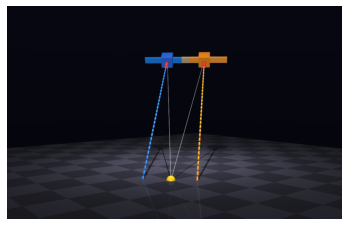

In [5]:
import cv2
import matplotlib.pyplot as plt
# Read the image
img = cv2.imread(r"D:\Semester 5 Projects\Drones\Dones_with_LOS_wrong.png")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 3. Display inline below the cell
plt.imshow(img_rgb)
plt.axis('off')  # Hides the grid axis lines
plt.show()
